# 🌎 GeoRisk AI — Evaluación CRISP-DM: Predicción de Deslizamientos en Bolivia
## Minería de Datos — Proyecto Académico
**Dataset:** `Dataset_10000_Bolivia_Sintetico.csv` · **Modelo base:** Regresión Logística · **Modelo principal (backend):** Random Forest (`modelo_deslizamientos.joblib`)

> **Nota sobre las clases:** la variable objetivo real es `deslizamiento_ocurrido`, **binaria** (0 = *No ocurre*, 1 = *Ocurre*); el modelo guardado tiene `classes_ = [0, 1]`. No existen niveles Bajo/Moderado/Alto/Muy Alto: se usan las 2 clases reales. Donde se habla del riesgo más grave ("Muy Alto"), el equivalente es la clase *Ocurre*.

**Datos de `train_model.py` (se replican exactamente):** objetivo `deslizamiento_ocurrido` · `train_test_split(test_size=0.2, random_state=42, stratify=y)` · numéricas `precipitacion_24h_mm, precipitacion_3d_mm, precipitacion_7d_mm, pendiente_grados, elevacion_m, humedad_pct` · categóricas `departamento, tipo_suelo, geologia` (One-Hot, `drop_first=True`) · el `StandardScaler` y **SMOTE** se aplican **después** del split y **solo sobre train**.

**Contenido:** 1 Negocio · 2 Métrica · 3 Datos · 4 Calidad · 5 Exploración · 6 Variable objetivo · 7 Preparación/Split · 8 Modelado · 9 Evaluación (LR vs RF) · 10 Interpretación · 11 Resumen · 12 Respuestas y conclusiones

In [1]:
# Imports y carga común: datos, artefactos .joblib y réplica exacta del preprocesamiento/split de train_model.py
import warnings; warnings.filterwarnings('ignore')
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             f1_score, precision_score, recall_score)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from IPython.display import display, Markdown

TARGET = 'deslizamiento_ocurrido'
VARS_CAT = ['departamento', 'tipo_suelo', 'geologia']
VARS_NUM = ['precipitacion_24h_mm', 'precipitacion_3d_mm', 'precipitacion_7d_mm',
            'pendiente_grados', 'elevacion_m', 'humedad_pct']
clases = ['No ocurre', 'Ocurre']
colores_clase = ['#2a9d8f', '#e63946']
RANDOM_STATE = 42

modelo = joblib.load('modelo_deslizamientos.joblib')
scaler = joblib.load('scaler.joblib')
columnas = joblib.load('columnas_modelo.joblib')
print('Modelo cargado:', type(modelo).__name__, '| clases del modelo:', modelo.classes_)

Modelo cargado: RandomForestClassifier | clases del modelo: [0 1]


## 1. COMPRENSIÓN DEL NEGOCIO

### Pregunta 1 — ¿Cuál es el problema concreto?

- **Problema:** predecir el riesgo de deslizamientos en Bolivia según condiciones climáticas (precipitación a 24 h, 3 d y 7 d, humedad) y geológicas/topográficas (pendiente, elevación, tipo de suelo, geología). El modelo entrega una clasificación binaria: *ocurre* / *no ocurre* deslizamiento (y una probabilidad asociada, `predict_proba`).
- **Decisión que apoya:** evacuaciones preventivas, planificación territorial de los municipios y alertas tempranas para Defensa Civil.
- **Criterio de éxito de negocio:** reducir víctimas y pérdidas materiales por deslizamientos, detectando zonas de riesgo con anticipación.
- **A quién afecta:** pobladores de zonas de ladera, municipios, Defensa Civil de Bolivia y SENAMHI (fuente de datos meteorológicos).
- **Cómo conecta:** el modelo clasifica zonas según variables medibles en tiempo real; su salida activa (o no) una alerta. *(Se pensó originalmente en 4 niveles Bajo/Moderado/Alto/Muy Alto; el modelo implementado es binario y la probabilidad de la clase "Ocurre" podría discretizarse en esos 4 niveles en una fase futura.)*
- **Objetivo de minería de datos:** entrenar modelos de clasificación (Regresión Logística como base y Random Forest como principal) que predigan si ocurrirá (1) o no (0) un deslizamiento.
- **Criterio de éxito de minería:** priorizar la **detección de eventos reales** (minimizar los falsos negativos), aceptando más falsas alarmas.

> *Este sistema es una herramienta de apoyo analítico: no reemplaza el criterio experto de Defensa Civil ni está listo para despliegue automatizado real.*

## 2. MÉTRICA PRINCIPAL

### Pregunta 2 — Métrica principal

- **Métrica principal de desempeño general: F1-score macro.** Promedia el F1 de cada clase con igual peso, de modo que ninguna clase domina pese al desbalance (≈56 % / 44 %).
- **Métrica de control para alertas: Recall de la clase *Ocurre*** (`Recall = VP / (VP + FN)`): mide qué proporción de los deslizamientos reales detecta el modelo; un falso negativo significa no avisar a la población.

$$F1_c = \frac{2\cdot Precision_c \cdot Recall_c}{Precision_c + Recall_c} \qquad F1_{macro} = \frac{1}{K}\sum_{c=1}^{K} F1_c$$

con $Precision_c = \frac{TP_c}{TP_c+FP_c}$, $Recall_c = \frac{TP_c}{TP_c+FN_c}$ y $K = 2$. **Unidades:** adimensionales, entre 0 y 1.

In [2]:
# Replica el preprocesamiento de train_model.py (OHE -> split -> scaler solo transform) y calcula F1-macro y Recall del Random Forest en test
df = pd.read_csv('Dataset_10000_Bolivia_Sintetico.csv')
X = pd.concat([df[VARS_NUM], pd.get_dummies(df[VARS_CAT], prefix=VARS_CAT, drop_first=True, dtype=int)], axis=1)
y = df[TARGET]
assert list(X.columns) == list(columnas), 'Columnas distintas a columnas_modelo.joblib'

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
X_test_scaled = scaler.transform(X_test)          # el scaler NO se re-ajusta
y_pred_rf = modelo.predict(X_test_scaled)

f1_macro = f1_score(y_test, y_pred_rf, average='macro')
print(f'Random Forest -> F1-macro: {f1_macro:.4f} | Recall (Ocurre): {recall_score(y_test, y_pred_rf):.4f}')
print('F1 por clase:', dict(zip(clases, f1_score(y_test, y_pred_rf, average=None).round(4))))

Random Forest -> F1-macro: 0.5739 | Recall (Ocurre): 0.5422
F1 por clase: {'No ocurre': np.float64(0.618), 'Ocurre': np.float64(0.5298)}


- **Valor observado (Random Forest):** F1-macro ≈ **0.574** y Recall de *Ocurre* ≈ **0.542**.
- **Acción para mejorarlas:** aumentar `n_estimators`, ajustar `max_depth`/`min_samples_leaf` con validación cruzada, bajar el umbral de `predict_proba` (más recall), o agregar más registros de la clase *Ocurre* y variables nuevas.
- **Aclaración:** son métricas de **desempeño del modelo**, **no de negocio**. La métrica de negocio es reducir víctimas y pérdidas.

## 3. COMPRENSIÓN DE LOS DATOS

### Pregunta 3 — Unidad de análisis y origen de los datos

In [3]:
# Carga el CSV sin filtros y muestra forma, tipos de datos y primeras filas
df = pd.read_csv('Dataset_10000_Bolivia_Sintetico.csv')
print("Shape:", df.shape)
print("\nTipos de datos:")
print(df.dtypes)
n_archivo = sum(1 for _ in open('Dataset_10000_Bolivia_Sintetico.csv', encoding='utf-8')) - 1
print(f"\nFilas en el archivo: {n_archivo} | filas cargadas: {len(df)} -> sin filtros: {n_archivo == len(df)}")
print("\nPrimeras filas:")
df.head(3)

Shape: (10000, 13)

Tipos de datos:
id_registro                      int64
departamento                       str
precipitacion_24h_mm           float64
precipitacion_3d_mm            float64
precipitacion_7d_mm            float64
pendiente_grados               float64
elevacion_m                    float64
humedad_pct                    float64
tipo_suelo                         str
geologia                           str
score_riesgo_bruto             float64
indice_riesgo_deslizamiento    float64
deslizamiento_ocurrido           int64
dtype: object

Filas en el archivo: 10000 | filas cargadas: 10000 -> sin filtros: True

Primeras filas:


,id_registro,departamento,precipitacion_24h_mm,precipitacion_3d_mm,precipitacion_7d_mm,pendiente_grados,elevacion_m,humedad_pct,tipo_suelo,geologia,score_riesgo_bruto,indice_riesgo_deslizamiento,deslizamiento_ocurrido
0,1,Tarija,7.882587,31.315267,5.265054,19.631351,3621.604689,42.770632,Arenoso,Sedimentaria,17.125458,38.821269,0
1,2,Oruro,8.403362,41.843080,162.713827,23.647557,3487.789940,58.060846,Arcilloso,Sedimentaria,19.559214,42.573938,0
2,3,Chuquisaca,13.212453,43.106140,254.204467,39.906789,3225.629864,34.607312,Franco,Sedimentaria,23.132418,48.083549,0


- **Qué representa una fila:** una observación de condiciones topográficas, climáticas y geológicas de un punto geográfico de Bolivia (de uno de sus departamentos) y si ocurrió un deslizamiento.
- **Origen:** dataset **sintético** generado (`Dataset_10000_Bolivia_Sintetico.py`) para simular condiciones reales bolivianas.
- **Registros:** 10 000 | **Variables:** 13 (`id_registro`, `departamento`, 3 precipitaciones, `pendiente_grados`, `elevacion_m`, `humedad_pct`, `tipo_suelo`, `geologia`, `score_riesgo_bruto`, `indice_riesgo_deslizamiento`, `deslizamiento_ocurrido`).
- **Filtros aplicados:** ninguno; el número de filas del archivo coincide con el del DataFrame.

## 4. CALIDAD DE LOS DATOS

### Pregunta 4 — Calidad de los datos

In [4]:
# Verifica nulos, duplicados, distribución del objetivo y rangos lógicos de las variables
print("=== Valores faltantes ===")
print(df.isnull().sum())
print("\n=== Duplicados ===")
print(f"Filas duplicadas: {df.duplicated().sum()}")
print("\n=== Distribución variable objetivo ===")
print(df[TARGET].value_counts())
print("\n=== Verificación de rangos lógicos ===")
reglas = {'precipitacion_24h_mm': (0, None), 'precipitacion_3d_mm': (0, None), 'precipitacion_7d_mm': (0, None),
          'pendiente_grados': (0, 90), 'humedad_pct': (0, 100), 'elevacion_m': (0, 6500)}
for col, (lo, hi) in reglas.items():
    fuera = int((df[col] < lo).sum() + ((df[col] > hi).sum() if hi is not None else 0))
    print(f'{col:22s} min={df[col].min():8.2f} max={df[col].max():8.2f} | fuera de [{lo}, {hi}]: {fuera}')
print("\n=== Coherencia de acumulados ===")
print('24h > 3d:', int((df.precipitacion_24h_mm > df.precipitacion_3d_mm).sum()),
      '| 3d > 7d:', int((df.precipitacion_3d_mm > df.precipitacion_7d_mm).sum()))

=== Valores faltantes ===
id_registro                    0
departamento                   0
precipitacion_24h_mm           0
precipitacion_3d_mm            0
precipitacion_7d_mm            0
pendiente_grados               0
elevacion_m                    0
humedad_pct                    0
tipo_suelo                     0
geologia                       0
score_riesgo_bruto             0
indice_riesgo_deslizamiento    0
deslizamiento_ocurrido         0
dtype: int64

=== Duplicados ===
Filas duplicadas: 0

=== Distribución variable objetivo ===
deslizamiento_ocurrido
0    5618
1    4382
Name: count, dtype: int64

=== Verificación de rangos lógicos ===
precipitacion_24h_mm   min=    0.00 max=  137.09 | fuera de [0, None]: 0
precipitacion_3d_mm    min=    0.00 max=  410.61 | fuera de [0, None]: 0
precipitacion_7d_mm    min=    0.00 max= 2066.28 | fuera de [0, None]: 0
pendiente_grados       min=    0.00 max=   82.13 | fuera de [0, 90]: 0
humedad_pct            min=    0.00 max=  100.00 | fu

**Hallazgos y acciones:**
- **Faltantes:** se verificó y *no se encontraron* valores nulos → no se imputó nada.
- **Duplicados:** se verificó y *no se encontraron* filas duplicadas → no se eliminó nada.
- **Rangos lógicos:** pendiente en [0°, 90°], humedad en [0 %, 100 %], precipitaciones ≥ 0 y elevación entre ≈500 y ≈5000 m → *no se encontraron* valores fuera de rango.
- **Coherencia de acumulados:** **sí hay incoherencia**: ≈2 500 registros (≈25 %) tienen precipitación 24 h > 3 d y ≈2 450 tienen 3 d > 7 d, algo imposible físicamente (el generador sintético simuló cada ventana de forma independiente). **No se corrigió** para no alterar los datos con los que se entrenó el modelo; queda como limitación.
- **Variable objetivo:** 5 618 *No ocurre* (56.2 %) vs 4 382 *Ocurre* (43.8 %): desbalance moderado, tratado con SMOTE y `class_weight='balanced'`.

### 4.1 Tratamiento
* **Numéricas:** imputación por mediana (robusta a atípicos). **Categóricas:** imputación por moda.
* Como se verificó que **no hay nulos ni duplicados**, el código siguiente es solo una salvaguarda preventiva y no modifica los datos.

In [5]:
# Salvaguarda preventiva: imputa nulos (si los hubiera) y elimina duplicados; con este dataset no cambia nada
filas_antes = len(df)
df[VARS_NUM] = df[VARS_NUM].fillna(df[VARS_NUM].median())
for col in VARS_CAT:
    df[col] = df[col].fillna(df[col].mode()[0])
df = df.drop_duplicates()
print(f'Nulos restantes: {int(df.isnull().sum().sum())} | filas antes: {filas_antes} | filas después: {len(df)}')

Nulos restantes: 0 | filas antes: 10000 | filas después: 10000


## 5. ANÁLISIS EXPLORATORIO

### 5.1 Vista general de las variables numéricas

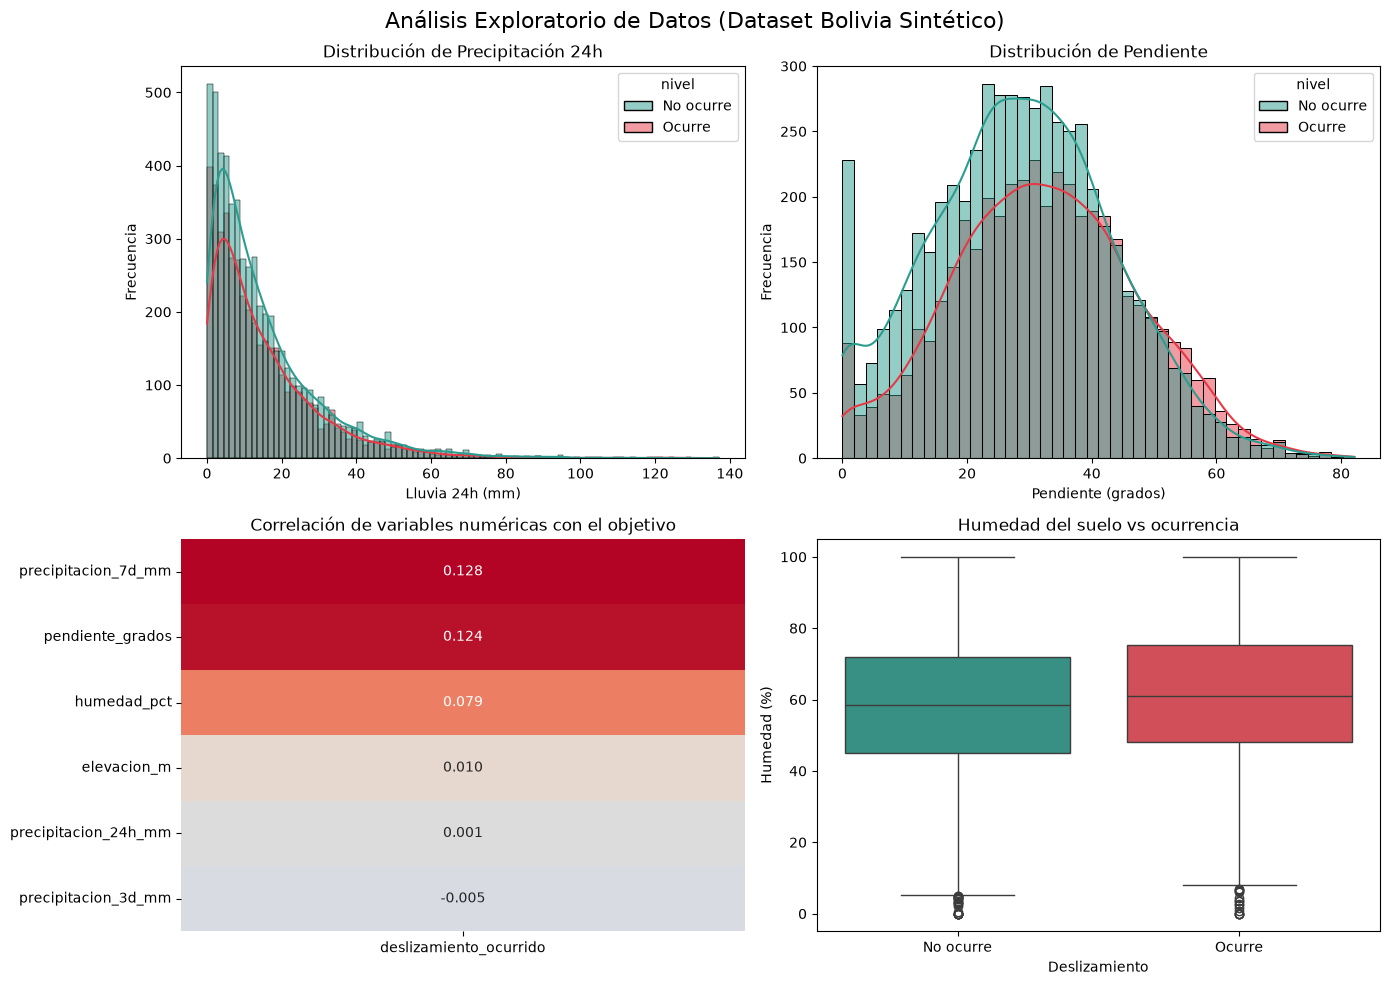

nivel                 No ocurre  Ocurre
precipitacion_24h_mm       10.4    10.5
precipitacion_3d_mm        31.6    30.3
precipitacion_7d_mm        88.6   114.9
pendiente_grados           28.7    32.1
elevacion_m              2726.6  2769.9
humedad_pct                58.4    61.0


In [6]:
# Panel 2x2: distribuciones de lluvia 24h y pendiente, correlación con el objetivo y boxplot de humedad
df['nivel'] = df[TARGET].map(dict(enumerate(clases)))
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.histplot(data=df, x='precipitacion_24h_mm', hue='nivel', hue_order=clases, palette=colores_clase, kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Distribución de Precipitación 24h'); axes[0, 0].set_xlabel('Lluvia 24h (mm)'); axes[0, 0].set_ylabel('Frecuencia')
sns.histplot(data=df, x='pendiente_grados', hue='nivel', hue_order=clases, palette=colores_clase, kde=True, ax=axes[0, 1])
axes[0, 1].set_title('Distribución de Pendiente'); axes[0, 1].set_xlabel('Pendiente (grados)'); axes[0, 1].set_ylabel('Frecuencia')
corr = df[VARS_NUM + [TARGET]].corr()[[TARGET]].drop(TARGET).sort_values(by=TARGET, ascending=False)
sns.heatmap(corr, annot=True, fmt='.3f', cmap='coolwarm', center=0, ax=axes[1, 0], cbar=False)
axes[1, 0].set_title('Correlación de variables numéricas con el objetivo')
sns.boxplot(data=df, x='nivel', y='humedad_pct', order=clases, hue='nivel', palette=dict(zip(clases, colores_clase)), legend=False, ax=axes[1, 1])
axes[1, 1].set_title('Humedad del suelo vs ocurrencia'); axes[1, 1].set_xlabel('Deslizamiento'); axes[1, 1].set_ylabel('Humedad (%)')
fig.suptitle('Análisis Exploratorio de Datos (Dataset Bolivia Sintético)', fontsize=16)
plt.tight_layout(); plt.show()
print(df.groupby('nivel')[VARS_NUM].median().round(1).T)

**Observaciones (con datos):** la precipitación de **24 h casi no distingue** las clases (medianas prácticamente iguales, ≈15 mm). Las variables que sí se diferencian, aunque de forma moderada, son la **lluvia acumulada a 7 días** (≈115 mm con deslizamiento vs ≈89 mm sin), la **pendiente** (≈32° vs ≈29°) y la **humedad** (≈61 % vs ≈58 %). Las correlaciones lineales con el objetivo son bajas, así que ninguna variable separa las clases por sí sola.

### 5.2 Hallazgo principal

### Pregunta 5 — Hallazgo interesante

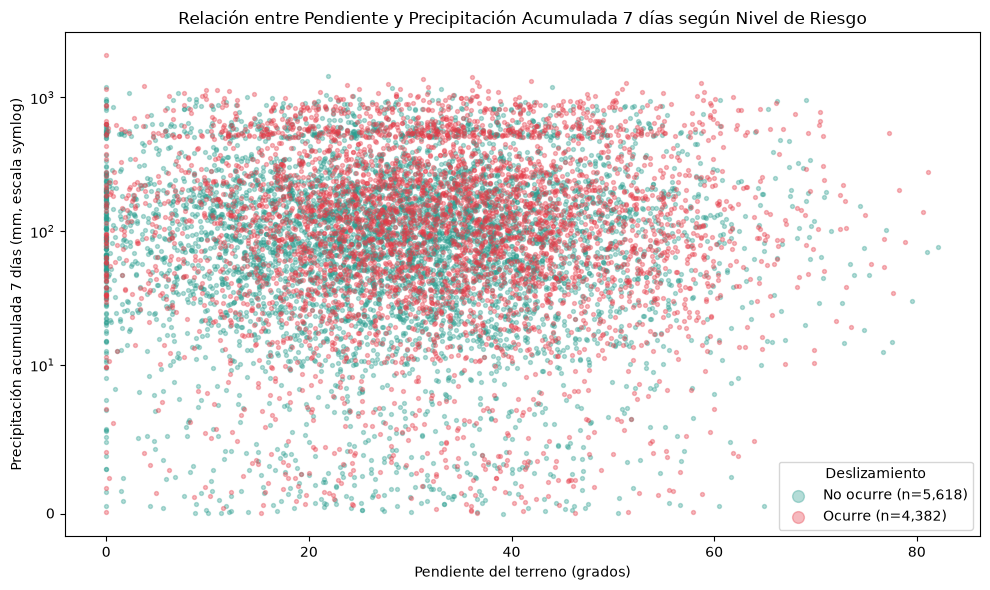

           pendiente_grados  precipitacion_7d_mm  humedad_pct
nivel                                                        
No ocurre              28.7                 88.6         58.4
Ocurre                 32.1                114.9         61.0

Tasa de deslizamiento por cuartil de pendiente (filas) y de lluvia 7d (columnas):
precipitacion_7d_mm    Q1    Q2    Q3    Q4
pendiente_grados                           
Q1                   0.34  0.31  0.34  0.47
Q2                   0.37  0.38  0.41  0.52
Q3                   0.41  0.37  0.43  0.55
Q4                   0.47  0.53  0.51  0.60


In [7]:
# Scatter de pendiente vs precipitación acumulada a 7 días, coloreado por ocurrencia de deslizamiento
df['nivel'] = df[TARGET].map(dict(enumerate(clases)))
plt.figure(figsize=(10, 6))
for nombre, color in zip(clases, colores_clase):
    sub = df[df['nivel'] == nombre]
    plt.scatter(sub['pendiente_grados'], sub['precipitacion_7d_mm'], s=8, alpha=0.35, c=color, label=f'{nombre} (n={len(sub):,})')
plt.yscale('symlog', linthresh=10)
plt.title('Relación entre Pendiente y Precipitación Acumulada 7 días según Nivel de Riesgo')
plt.xlabel('Pendiente del terreno (grados)')
plt.ylabel('Precipitación acumulada 7 días (mm, escala symlog)')
plt.legend(title='Deslizamiento', markerscale=3)
plt.tight_layout(); plt.show()
print(df.groupby('nivel')[['pendiente_grados', 'precipitacion_7d_mm', 'humedad_pct']].median().round(1))
print('\nTasa de deslizamiento por cuartil de pendiente (filas) y de lluvia 7d (columnas):')
print(pd.crosstab(pd.qcut(df.pendiente_grados, 4, labels=['Q1','Q2','Q3','Q4']),
                  pd.qcut(df.precipitacion_7d_mm, 4, labels=['Q1','Q2','Q3','Q4']),
                  values=df[TARGET], aggfunc='mean').round(2))

- **Patrón observado:** las medianas son mayores en los registros con deslizamiento (pendiente ≈32° vs ≈29°; lluvia 7 d ≈115 mm vs ≈89 mm). En la tabla por cuartiles la tasa de deslizamiento sube cuando coinciden pendiente y lluvia altas (esquina Q4–Q4). Sin embargo, las nubes de puntos se **solapan mucho**: ninguna variable por sí sola separa las clases.
- **Por qué importa:** coincide con la física de laderas (más pendiente = más esfuerzo cortante; más lluvia acumulada = suelo saturado y menos resistencia), y muestra que el riesgo surge de la **combinación** de factores, no de uno solo.
- **Implicación práctica:** el sistema de alerta debe combinar varias variables (lo que justifica un modelo multivariable como Random Forest) y priorizar el monitoreo de laderas empinadas durante lluvias acumuladas altas.
- **Cautela:** el solapamiento anticipa un desempeño limitado del modelo con estas variables.

## 6. VARIABLE OBJETIVO PARA CLASIFICACIÓN

### Pregunta 6 — Variable objetivo para clasificación

deslizamiento_ocurrido
0    5618
1    4382
Name: count, dtype: int64


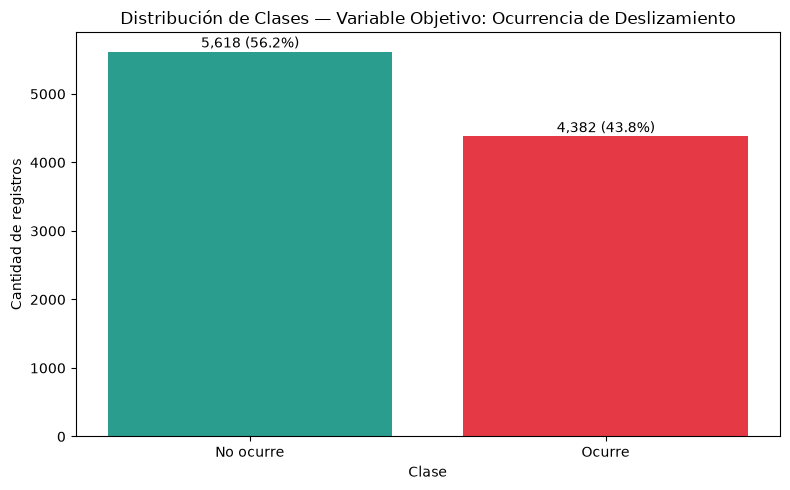

In [8]:
# Distribución de clases de la variable objetivo (orden lógico: No ocurre, Ocurre)
print(df[TARGET].value_counts())
conteos = df[TARGET].map(dict(enumerate(clases))).value_counts().reindex(clases)
plt.figure(figsize=(8, 5))
barras = plt.bar(conteos.index, conteos.values, color=colores_clase)
for b, v in zip(barras, conteos.values):
    plt.text(b.get_x() + b.get_width() / 2, v + 60, f'{v:,} ({v/len(df):.1%})', ha='center')
plt.title('Distribución de Clases — Variable Objetivo: Ocurrencia de Deslizamiento')
plt.xlabel('Clase'); plt.ylabel('Cantidad de registros')
plt.tight_layout(); plt.show()

**¿Por qué Random Forest?**
- Maneja clasificación binaria y multiclase (útil si luego se pasa a 4 niveles).
- Acepta variables mixtas (numéricas y dummies) sin escalar obligatoriamente.
- Robusto a ruido y sobreajuste; **no requiere normalidad** ni linealidad.
- Captura interacciones (lluvia × pendiente) automáticamente.
- Genera **importancia de variables**, útil para explicar el modelo.
- Funciona bien con SMOTE + `class_weight='balanced'` para el desbalance (≈56/44).

## 7. PREPARACIÓN DE LOS DATOS Y PREVENCIÓN DE DATA LEAKAGE

### Pregunta 7 — Separación entrenamiento / prueba

In [9]:
# Muestra formas de train/test, proporción real y random_state (réplica de train_model.py)
print('random_state usado:', RANDOM_STATE, '| test_size = 0.2 | stratify = y')
print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('y_train:', y_train.shape, '| y_test:', y_test.shape)
print(f'Proporción real: {len(X_train)/len(X):.0%} train / {len(X_test)/len(X):.0%} test')
print('Tasa de "Ocurre" -> train: %.3f | test: %.3f' % (y_train.mean(), y_test.mean()))

from sklearn.preprocessing import StandardScaler
chk = StandardScaler().fit(X_train)   # solo con train
print('scaler.joblib == scaler ajustado solo con X_train:', np.allclose(chk.mean_, scaler.mean_) and np.allclose(chk.scale_, scaler.scale_))

random_state usado: 42 | test_size = 0.2 | stratify = y
X_train: (8000, 16) | X_test: (2000, 16)
y_train: (8000,) | y_test: (2000,)
Proporción real: 80% train / 20% test
Tasa de "Ocurre" -> train: 0.438 | test: 0.438
scaler.joblib == scaler ajustado solo con X_train: True


In [10]:
# Escala train con el scaler (ajustado solo en train) y aplica SMOTE SOLO al entrenamiento (igual que train_model.py)
X_train_scaled = scaler.transform(X_train)     # equivale a fit_transform(X_train): el scaler guardado se ajustó solo con train
print('Distribución ANTES de SMOTE (train):');   print(y_train.value_counts().to_string())
smote = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)
print('\nDistribución DESPUÉS de SMOTE (solo train):'); print(y_train_bal.value_counts().to_string())
print(f'\nRegistros de entrenamiento balanceado: {X_train_bal.shape[0]} | Registros de prueba (sin tocar): {X_test_scaled.shape[0]}')

Distribución ANTES de SMOTE (train):
deslizamiento_ocurrido
0    4494
1    3506

Distribución DESPUÉS de SMOTE (solo train):
deslizamiento_ocurrido
0    4494
1    4494

Registros de entrenamiento balanceado: 8988 | Registros de prueba (sin tocar): 2000


**Data leakage** = que información del conjunto de prueba influya en el entrenamiento, inflando el desempeño.
- El `StandardScaler` se ajusta **solo con `X_train`** (`.fit_transform`).
- En `X_test` se aplica `.transform` con la media y desviación de train, **sin re-ajustar**.
- Así las estadísticas del test no contaminan el entrenamiento. Igualmente, SMOTE se aplica únicamente a train, de modo que el test conserva su distribución real.
- **Nota de comparación justa:** ambos modelos usan **las mismas 16 variables** y el mismo split. Se excluyen `id_registro`, `indice_riesgo_deslizamiento` y `score_riesgo_bruto` (derivados del propio riesgo/identificadores), para no filtrar información del objetivo.

## 8. MODELADO
- **Modelo base — Regresión Logística:** interpretable mediante sus coeficientes.
- **Modelo principal — Random Forest** (`n_estimators=100, max_depth=10, class_weight='balanced'`), ya entrenado por `train_model.py` y cargado desde `modelo_deslizamientos.joblib`.

In [11]:
# Entrena la Regresión Logística base con los mismos datos balanceados y genera predicciones de ambos modelos sobre el test
modelo_logistico = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
modelo_logistico.fit(X_train_bal, y_train_bal)

y_pred_lr = modelo_logistico.predict(X_test_scaled)
y_pred_rf = modelo.predict(X_test_scaled)
print('Regresión Logística entrenada y Random Forest cargado. Predicciones listas sobre', len(y_test), 'registros de prueba.')

Regresión Logística entrenada y Random Forest cargado. Predicciones listas sobre 2000 registros de prueba.


## 9. EVALUACIÓN DEL MODELO

### 9.1 Comparación Regresión Logística vs Random Forest

,Accuracy,Precision,Recall (Ocurre),F1 (Ocurre),F1-macro,Falsos negativos,Falsas alarmas
Regresión Logística,0.5835,0.5232,0.5525,0.5375,0.5793,392.0,441.0
Random Forest,0.5785,0.5180,0.5422,0.5298,0.5739,401.0,442.0


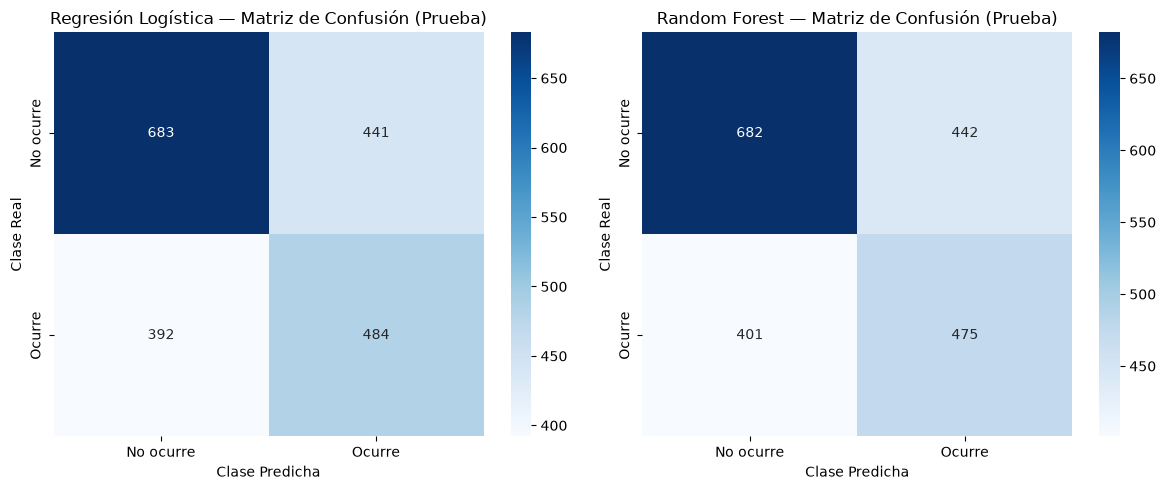

In [12]:
# Tabla comparativa de métricas y matrices de confusión lado a lado (conjunto de prueba)
resultados = {}
for nombre, pred in [('Regresión Logística', y_pred_lr), ('Random Forest', y_pred_rf)]:
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, pred).ravel()
    resultados[nombre] = {'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred),
                          'Recall (Ocurre)': recall_score(y_test, pred), 'F1 (Ocurre)': f1_score(y_test, pred),
                          'F1-macro': f1_score(y_test, pred, average='macro'),
                          'Falsos negativos': fn_, 'Falsas alarmas': fp_}
tabla_comp = pd.DataFrame(resultados).T
display(tabla_comp.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (nombre, pred) in zip(axes, [('Regresión Logística', y_pred_lr), ('Random Forest', y_pred_rf)]):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', xticklabels=clases, yticklabels=clases, ax=ax)
    ax.set_title(f'{nombre} — Matriz de Confusión (Prueba)'); ax.set_ylabel('Clase Real'); ax.set_xlabel('Clase Predicha')
plt.tight_layout(); plt.show()

**Lectura de la comparación:** ambos modelos rinden **prácticamente igual** (accuracy ≈ 0.58, F1-macro ≈ 0.57–0.58); la Regresión Logística es incluso ligeramente superior (recall 0.553 vs 0.542; 392 vs 401 falsos negativos). Es decir, **el Random Forest no aporta una mejora real** sobre el modelo base con estas variables: el límite parece estar en la información de los datos (señal débil y solapamiento entre clases), no en la complejidad del algoritmo. Se mantiene el Random Forest por ser el que usa el backend y por entregar importancia de variables y árboles auditables.

### Pregunta 9 — Desempeño del Random Forest en el conjunto de prueba

In [13]:
# Exactitud y reporte de clasificación por clase del Random Forest, más el análisis del error crítico (falsos negativos)
print("=== ACCURACY ===")
print(f"Exactitud: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"F1-macro : {f1_score(y_test, y_pred_rf, average='macro'):.4f}")
print("\n=== REPORTE COMPLETO ===")
print(classification_report(y_test, y_pred_rf, target_names=clases))
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_rf).ravel()
print(f'Falsos negativos (real=Ocurre, predicho=No ocurre): {fn} de {fn+tp} ({fn/(fn+tp):.1%}) | Falsas alarmas: {fp} de {fp+tn} ({fp/(fp+tn):.1%})')

=== ACCURACY ===
Exactitud: 0.5785
F1-macro : 0.5739

=== REPORTE COMPLETO ===
              precision    recall  f1-score   support

   No ocurre       0.63      0.61      0.62      1124
      Ocurre       0.52      0.54      0.53       876

    accuracy                           0.58      2000
   macro avg       0.57      0.57      0.57      2000
weighted avg       0.58      0.58      0.58      2000

Falsos negativos (real=Ocurre, predicho=No ocurre): 401 de 876 (45.8%) | Falsas alarmas: 442 de 1124 (39.3%)


- **Resultados reales:** accuracy = **0.5785** y F1-macro = **0.5739** (2 000 registros de prueba). Es un desempeño **modesto**, apenas superior a predecir siempre "No ocurre" (56.2 %).
- **Error más crítico a reducir:** el **falso negativo** en la clase de riesgo (equivalente a "Muy Alto"): predecir zona segura cuando el riesgo es real = potencial pérdida de vidas. Hay **401 de 876** eventos reales no detectados (45.8 %).
- **Interpretación de la matriz:** el modelo confunde en ambos sentidos: 442 "No ocurre" fueron marcados como "Ocurre" (falsas alarmas, 39 %) y 401 "Ocurre" como "No ocurre". El recall de *Ocurre* es 0.54 y su precisión 0.52. Para alertas conviene priorizar el recall de *Ocurre* (por ejemplo bajando el umbral de `predict_proba`), aceptando más falsas alarmas.

## 10. INTERPRETACIÓN DE LOS MODELOS

### 10.1 Coeficientes de la Regresión Logística (modelo base)

,Variable,Coeficiente,Interpretación
3,pendiente_grados,0.2857,Aumenta tendencia hacia Ocurre (1)
2,precipitacion_7d_mm,0.2401,Aumenta tendencia hacia Ocurre (1)
5,humedad_pct,0.1674,Aumenta tendencia hacia Ocurre (1)
12,tipo_suelo_Franco,-0.0487,Aumenta tendencia hacia No ocurre (0)
13,tipo_suelo_Limoso,-0.0417,Aumenta tendencia hacia No ocurre (0)
11,tipo_suelo_Arenoso,-0.0383,Aumenta tendencia hacia No ocurre (0)
7,departamento_La Paz,-0.0307,Aumenta tendencia hacia No ocurre (0)
14,geologia_Sedimentaria,0.0300,Aumenta tendencia hacia Ocurre (1)
0,precipitacion_24h_mm,-0.0276,Aumenta tendencia hacia No ocurre (0)
1,precipitacion_3d_mm,-0.0252,Aumenta tendencia hacia No ocurre (0)


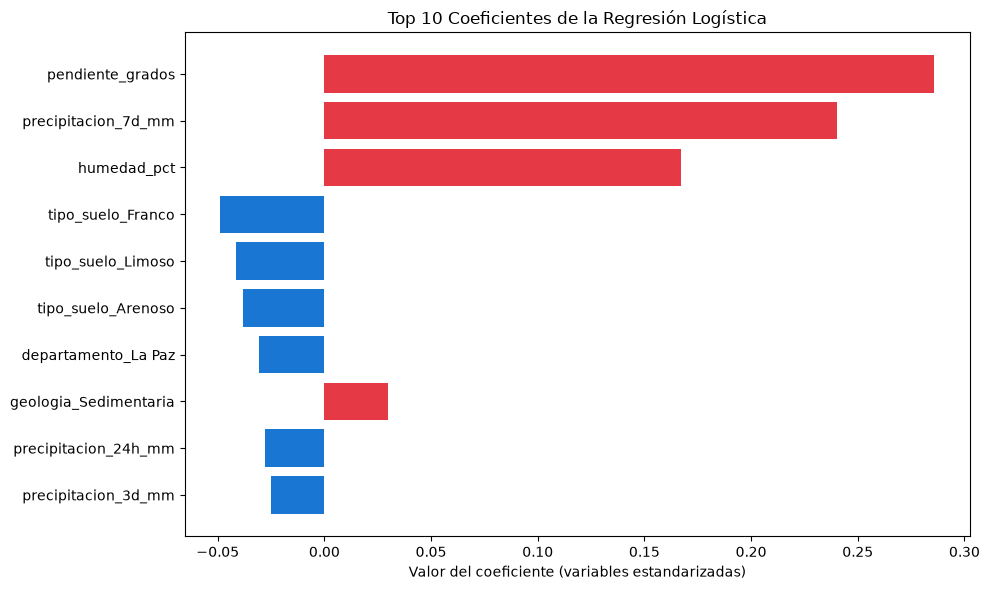

In [14]:
# Top 10 coeficientes de la Regresión Logística (variables estandarizadas, por lo que son comparables entre sí)
df_coef = pd.DataFrame({'Variable': X.columns, 'Coeficiente': modelo_logistico.coef_[0]})
df_coef = df_coef.reindex(df_coef['Coeficiente'].abs().sort_values(ascending=False).index).head(10)
df_coef['Interpretación'] = np.where(df_coef['Coeficiente'] > 0, 'Aumenta tendencia hacia Ocurre (1)', 'Aumenta tendencia hacia No ocurre (0)')
display(df_coef.round(4))

plt.figure(figsize=(10, 6))
colores_coef = ['#e63946' if c > 0 else '#1976d2' for c in df_coef['Coeficiente']]
plt.barh(df_coef['Variable'][::-1], df_coef['Coeficiente'][::-1], color=colores_coef[::-1])
plt.title('Top 10 Coeficientes de la Regresión Logística'); plt.xlabel('Valor del coeficiente (variables estandarizadas)')
plt.tight_layout(); plt.show()

Los coeficientes positivos se asocian a mayor probabilidad estimada de *Ocurre* y los negativos a *No ocurre*. Es una asociación del modelo, no causalidad.

### 10.2 Importancia de variables del Random Forest

### Pregunta 8 — Variables más importantes

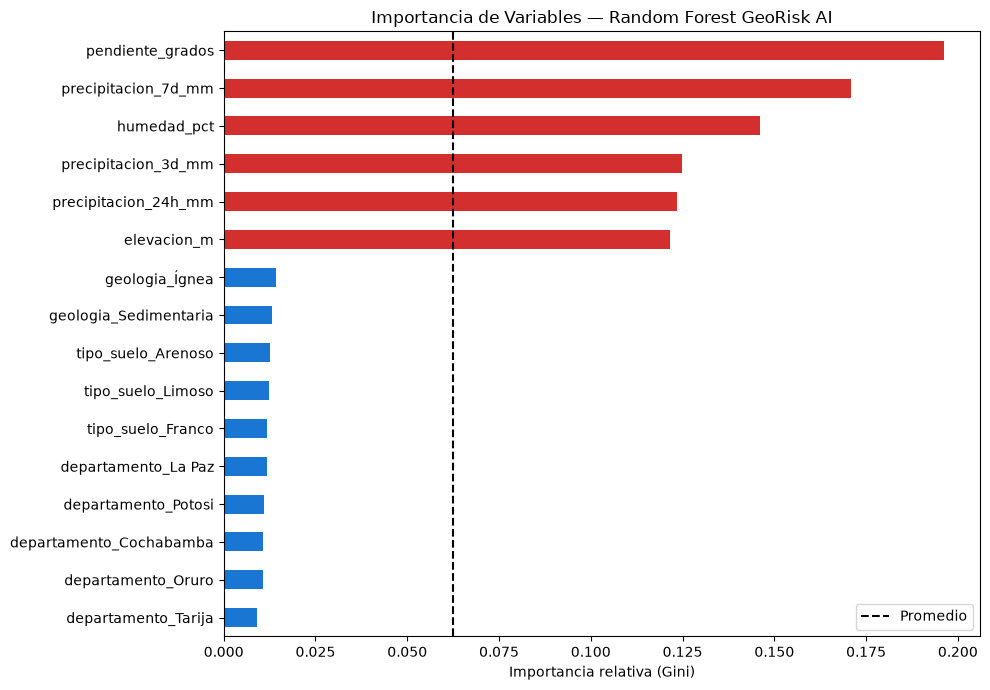

pendiente_grados        19.6 %
precipitacion_7d_mm     17.1 %
humedad_pct             14.6 %
precipitacion_3d_mm     12.5 %
precipitacion_24h_mm    12.3 %
dtype: str


In [15]:
# Importancia de variables (Gini) del Random Forest cargado, con la media como referencia
importancias = pd.Series(modelo.feature_importances_, index=columnas)
importancias_sorted = importancias.sort_values(ascending=True)

plt.figure(figsize=(10, 7))
cols_barra = ['#d32f2f' if v > importancias.mean() else '#1976d2' for v in importancias_sorted.values]
importancias_sorted.plot(kind='barh', color=cols_barra)
plt.title('Importancia de Variables — Random Forest GeoRisk AI')
plt.xlabel('Importancia relativa (Gini)')
plt.axvline(importancias.mean(), color='black', linestyle='--', label='Promedio')
plt.legend(); plt.tight_layout(); plt.show()
print((importancias.sort_values(ascending=False).head(5) * 100).round(1).astype(str) + ' %')

Las 3 variables con mayor importancia relativa:
1. **`pendiente_grados` (≈19.6 %):** la inclinación de la ladera es la variable con mayor importancia, lo cual es consistente con la física de deslizamientos (mayor esfuerzo cortante), aunque no implica causalidad directa en el modelo.
2. **`precipitacion_7d_mm` (≈17.1 %):** la lluvia acumulada de una semana se asocia al riesgo; es consistente con la saturación del suelo y la pérdida de resistencia.
3. **`humedad_pct` (≈14.6 %):** la humedad del suelo también aporta, en línea con la saturación previa a un evento.

La importancia mide la **contribución al modelo, no un efecto causal**. Además está repartida: las cinco principales (incluyendo precipitación 3 d y 24 h) rondan 12–20 %.

### 10.3 Un árbol del Random Forest

### Pregunta 10 — Visualización del árbol de decisión

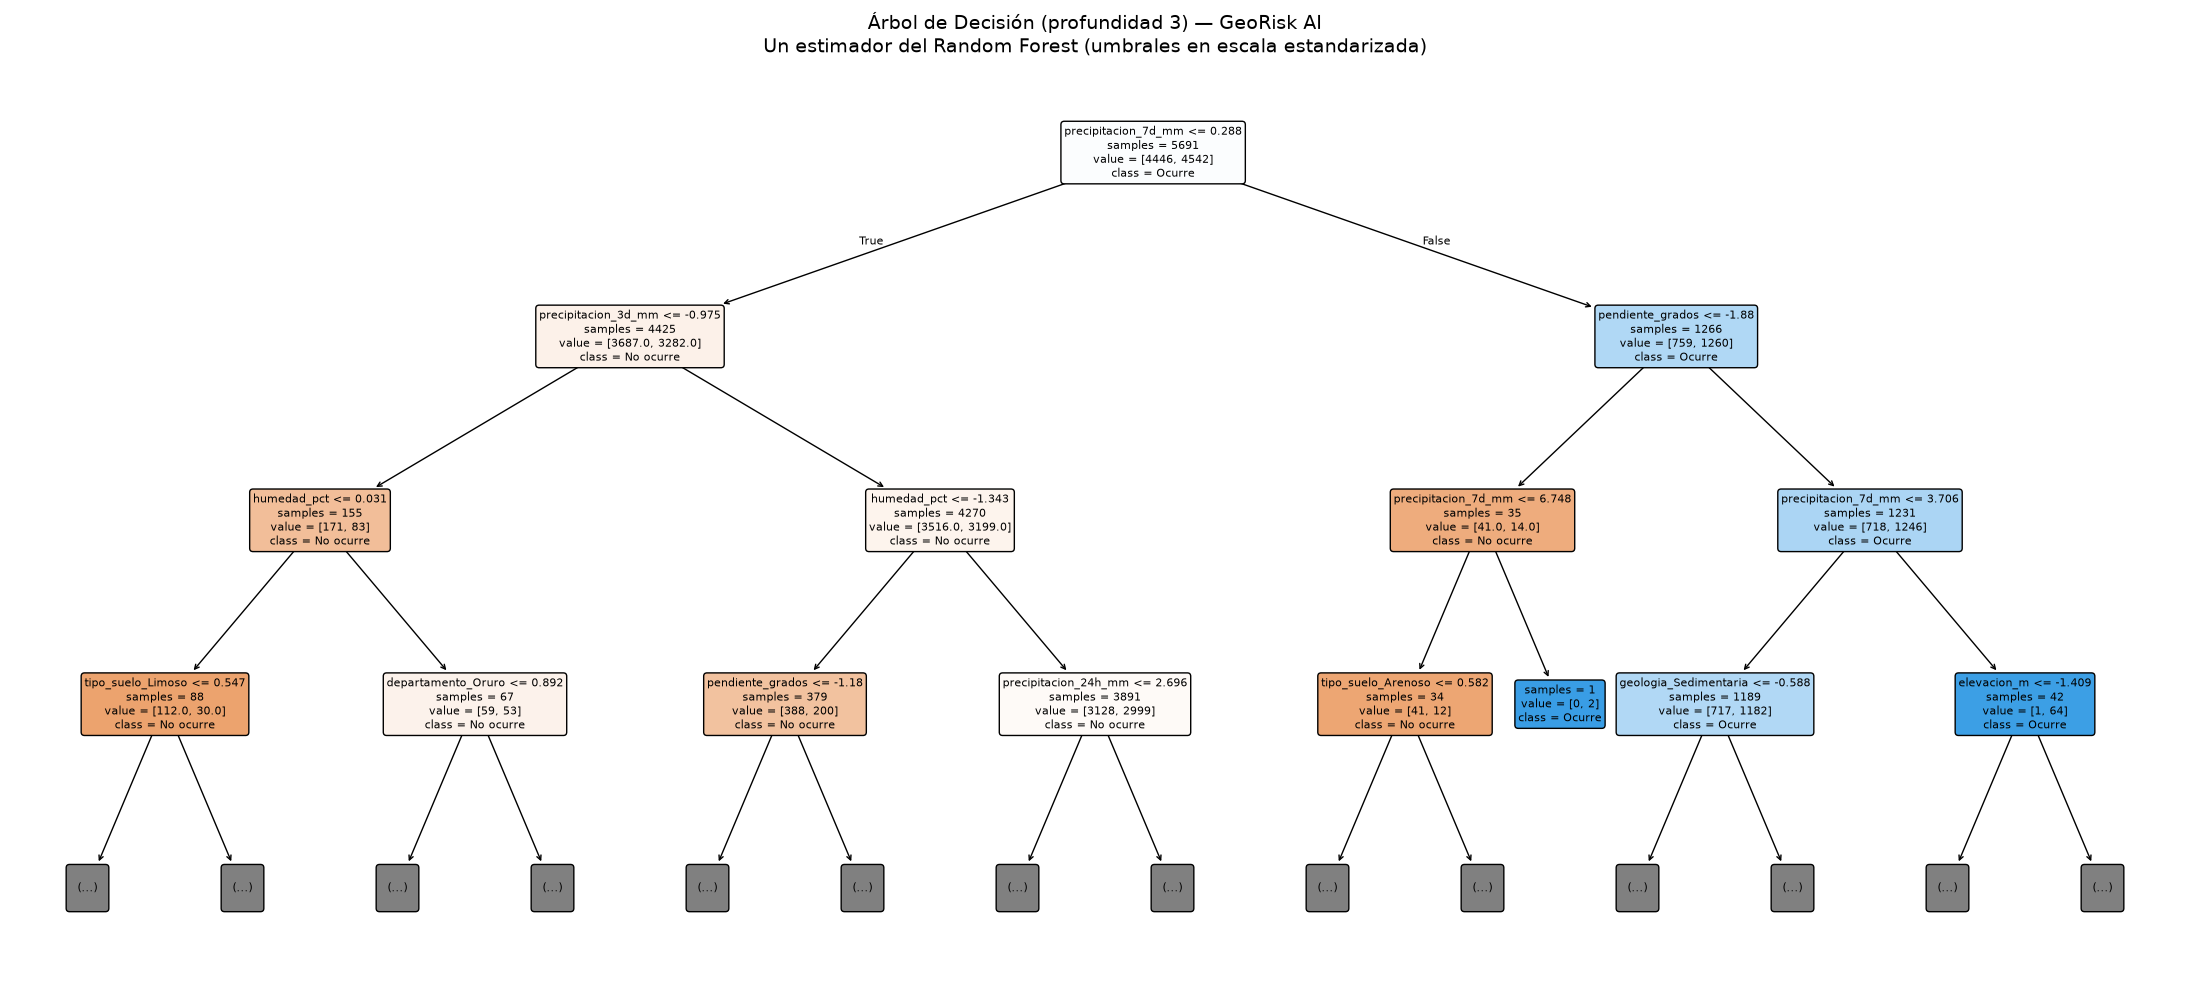

Árbol guardado como arbol_decision_georisk.png
precipitacion_7d_mm <= 240.9
precipitacion_3d_mm <= 1.6
humedad_pct <= 60.2
Proporción [No ocurre, Ocurre] en ese nodo: [0.79 0.21]


In [16]:
# Dibuja el primer árbol del Random Forest (profundidad 3), lo guarda como PNG e imprime una ruta en unidades reales
from sklearn.tree import plot_tree

un_arbol = modelo.estimators_[0]
plt.figure(figsize=(22, 10))
plot_tree(un_arbol, max_depth=3, feature_names=list(columnas), class_names=clases,
          filled=True, fontsize=8, rounded=True, impurity=False)
plt.title('Árbol de Decisión (profundidad 3) — GeoRisk AI\n'
          'Un estimador del Random Forest (umbrales en escala estandarizada)', fontsize=14)
plt.tight_layout()
plt.savefig('arbol_decision_georisk.png', dpi=150, bbox_inches='tight')
plt.show()
print("Árbol guardado como arbol_decision_georisk.png")

# Ruta por la rama "<=": umbrales de variables numéricas convertidos a unidades reales con el scaler
t = un_arbol.tree_; nodo = 0
for _ in range(3):
    f = t.feature[nodo]; nombre = columnas[f]; thr = t.threshold[nodo]
    if nombre in VARS_NUM:
        print(f'{nombre} <= {thr * scaler.scale_[f] + scaler.mean_[f]:.1f}')
    else:
        print(f'{nombre} <= {thr:.3f} (dummy)')
    nodo = t.children_left[nodo]
print('Proporción [No ocurre, Ocurre] en ese nodo:', t.value[nodo][0].round(2))

- **Ruta raíz → hoja (rama izquierda):** si la **lluvia acumulada de 7 días ≤ ≈241 mm**, **y** la lluvia de 3 días es mínima (≤ ≈1.6 mm), **y** la **humedad del suelo ≤ ≈60 %**, el árbol clasifica **"No ocurre"** (≈79 % de las muestras del nodo): una semana poco lluviosa y suelo no saturado no activa la ladera. La lectura contraria (más lluvia acumulada y suelo más húmedo) empuja hacia "Ocurre" y activaría la alerta.
- **Qué aporta:** permite **auditar** las decisiones del modelo: qué variables usa primero y con qué umbrales, y contrastarlas con el criterio de geólogos y Defensa Civil.
- **Limitación:** es **un solo árbol de 100**, truncado a profundidad 3; el ensemble decide combinando todos los árboles, por lo que esta figura ilustra la lógica pero no reemplaza al modelo completo.

## 11. DASHBOARD / RESUMEN VISUAL

In [17]:
# Resumen ejecutivo con los valores reales de ambos modelos
total_registros, total_variables = df.shape[0], df.shape[1] - 1   # -1: columna auxiliar 'nivel' creada en la exploración
casos_pos = int(df[TARGET].sum()); casos_neg = total_registros - casos_pos
r = tabla_comp
display(Markdown(f"""
### 📊 Resumen Ejecutivo
| Dato | Valor |
|---|---|
| **Total registros** | {total_registros:,} |
| **Total variables** | {total_variables} |
| **Sin deslizamiento** | {casos_neg:,} ({casos_neg/total_registros:.1%}) |
| **Con deslizamiento** | {casos_pos:,} ({casos_pos/total_registros:.1%}) |

### 📈 Desempeño en prueba (20 %)
| Indicador | Regresión Logística | Random Forest |
|---|---|---|
| **Accuracy** | {r.loc['Regresión Logística','Accuracy']:.4f} | {r.loc['Random Forest','Accuracy']:.4f} |
| **Recall (Ocurre)** | {r.loc['Regresión Logística','Recall (Ocurre)']:.4f} | {r.loc['Random Forest','Recall (Ocurre)']:.4f} |
| **Precision (Ocurre)** | {r.loc['Regresión Logística','Precision']:.4f} | {r.loc['Random Forest','Precision']:.4f} |
| **F1-macro** | {r.loc['Regresión Logística','F1-macro']:.4f} | {r.loc['Random Forest','F1-macro']:.4f} |
| **Falsos negativos (omitidos)** | {int(r.loc['Regresión Logística','Falsos negativos'])} | {int(r.loc['Random Forest','Falsos negativos'])} |
| **Falsas alarmas** | {int(r.loc['Regresión Logística','Falsas alarmas'])} | {int(r.loc['Random Forest','Falsas alarmas'])} |
"""))


### 📊 Resumen Ejecutivo
| Dato | Valor |
|---|---|
| **Total registros** | 10,000 |
| **Total variables** | 13 |
| **Sin deslizamiento** | 5,618 (56.2%) |
| **Con deslizamiento** | 4,382 (43.8%) |

### 📈 Desempeño en prueba (20 %)
| Indicador | Regresión Logística | Random Forest |
|---|---|---|
| **Accuracy** | 0.5835 | 0.5785 |
| **Recall (Ocurre)** | 0.5525 | 0.5422 |
| **Precision (Ocurre)** | 0.5232 | 0.5180 |
| **F1-macro** | 0.5793 | 0.5739 |
| **Falsos negativos (omitidos)** | 392 | 401 |
| **Falsas alarmas** | 441 | 442 |


## 12. RESPUESTAS PARA LA EVALUACIÓN CRISP-DM Y CONCLUSIONES

In [18]:
# Respuestas a las preguntas de la evaluación, con los valores reales obtenidos
rf, lr = tabla_comp.loc['Random Forest'], tabla_comp.loc['Regresión Logística']
imp_top = importancias.sort_values(ascending=False)
display(Markdown(f"""
**1. Problema y decisión:** predecir si ocurrirá un deslizamiento según condiciones climáticas y geológicas; apoya evacuaciones preventivas, planificación territorial y alertas tempranas de Defensa Civil.

**2. Métrica principal:** F1-macro (desempeño general) y Recall de *Ocurre* (control de alertas). Random Forest: F1-macro **{rf['F1-macro']:.4f}**, Recall **{rf['Recall (Ocurre)']:.4f}**.

**3. Unidad de análisis y datos:** una observación de condiciones de un punto de Bolivia; dataset **sintético** de {total_registros:,} registros y {total_variables} variables, sin filtros.

**4. Calidad:** se verificó y no hay nulos ni duplicados ni rangos inválidos; sí hay incoherencia entre acumulados de lluvia (24 h > 3 d y 3 d > 7 d en ≈25 % de filas), que no se corrigió.

**5. Hallazgo exploratorio:** la lluvia de 24 h casi no distingue las clases; pendiente (≈32° vs ≈29°), lluvia de 7 días (≈115 vs ≈89 mm) y humedad sí, pero con fuerte solapamiento.

**6. Variable objetivo y modelo:** `deslizamiento_ocurrido` (binaria); Random Forest como modelo principal y Regresión Logística como base.

**7. Separación train/test:** 80/20, `random_state=42`, estratificada; scaler y SMOTE ajustados solo con train (sin data leakage).

**8. Variables más importantes (RF):** `{imp_top.index[0]}` ({imp_top.iloc[0]:.1%}), `{imp_top.index[1]}` ({imp_top.iloc[1]:.1%}) y `{imp_top.index[2]}` ({imp_top.iloc[2]:.1%}); asociación, no causalidad.

**9. Desempeño en prueba:** Random Forest accuracy **{rf['Accuracy']:.4f}**, {int(rf['Falsos negativos'])} falsos negativos; Regresión Logística accuracy **{lr['Accuracy']:.4f}**, {int(lr['Falsos negativos'])} falsos negativos. Desempeño modesto y similar.

**10. Árbol de decisión:** permite auditar umbrales (p. ej. poca lluvia acumulada y suelo no saturado → *No ocurre*); es un árbol de 100, no el modelo completo.
"""))


**1. Problema y decisión:** predecir si ocurrirá un deslizamiento según condiciones climáticas y geológicas; apoya evacuaciones preventivas, planificación territorial y alertas tempranas de Defensa Civil.

**2. Métrica principal:** F1-macro (desempeño general) y Recall de *Ocurre* (control de alertas). Random Forest: F1-macro **0.5739**, Recall **0.5422**.

**3. Unidad de análisis y datos:** una observación de condiciones de un punto de Bolivia; dataset **sintético** de 10,000 registros y 13 variables, sin filtros.

**4. Calidad:** se verificó y no hay nulos ni duplicados ni rangos inválidos; sí hay incoherencia entre acumulados de lluvia (24 h > 3 d y 3 d > 7 d en ≈25 % de filas), que no se corrigió.

**5. Hallazgo exploratorio:** la lluvia de 24 h casi no distingue las clases; pendiente (≈32° vs ≈29°), lluvia de 7 días (≈115 vs ≈89 mm) y humedad sí, pero con fuerte solapamiento.

**6. Variable objetivo y modelo:** `deslizamiento_ocurrido` (binaria); Random Forest como modelo principal y Regresión Logística como base.

**7. Separación train/test:** 80/20, `random_state=42`, estratificada; scaler y SMOTE ajustados solo con train (sin data leakage).

**8. Variables más importantes (RF):** `pendiente_grados` (19.6%), `precipitacion_7d_mm` (17.1%) y `humedad_pct` (14.6%); asociación, no causalidad.

**9. Desempeño en prueba:** Random Forest accuracy **0.5785**, 401 falsos negativos; Regresión Logística accuracy **0.5835**, 392 falsos negativos. Desempeño modesto y similar.

**10. Árbol de decisión:** permite auditar umbrales (p. ej. poca lluvia acumulada y suelo no saturado → *No ocurre*); es un árbol de 100, no el modelo completo.


### Conclusiones finales

**3 hallazgos principales**
1. **Variables más asociadas al riesgo:** pendiente (19.6 %), lluvia acumulada a 7 días (17.1 %) y humedad (14.6 %), coherentes con la física de deslizamientos; la lluvia de 24 h aporta poco por sí sola y ninguna variable separa las clases por sí misma.
2. **Desempeño modesto y similar entre modelos:** accuracy ≈ 0.58 y F1-macro ≈ 0.57–0.58; el Random Forest (401 falsos negativos de 876) **no supera** a la Regresión Logística (392). La limitación está en la señal de los datos, no en el algoritmo.
3. **Datos limpios pero sintéticos:** sin nulos, duplicados ni rangos inválidos, con desbalance moderado (56.2 % / 43.8 %), pero con ≈25 % de registros con acumulados de lluvia físicamente incoherentes.

**Recomendación práctica para Defensa Civil y municipios:** usar el modelo solo como **apoyo de priorización**, no como decisor único: bajar el umbral de probabilidad para maximizar la detección de eventos (aceptando más falsas alarmas) y combinarlo con umbrales de lluvia acumulada y pendiente en un protocolo de alerta escalonado, con verificación en campo antes de evacuar.

**Limitaciones**
- Datos **sintéticos**: el desempeño real puede ser muy distinto; se requiere **validación con datos reales de campo** (inventarios de deslizamientos, SENAMHI, Defensa Civil).
- Modelo binario (no 4 niveles); falta validación cruzada, ajuste de hiperparámetros y calibración de probabilidades; sin dimensión temporal ni espacial fina.
- Las importancias, coeficientes y árboles muestran asociación, **no causalidad**.